In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,919 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updat

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app pkg-config --cflags --libs= opencv4 -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

g++: error: missing argument to ‘--libs=’
g++: error: unrecognized command-line option ‘--cflags’
/bin/bash: line 1: ./app: No such file or directory


Görüntü Boyutu: (474, 474)
Eşleşen piksellerin mutlak farklarının toplamı (Hata Değeri): 113278


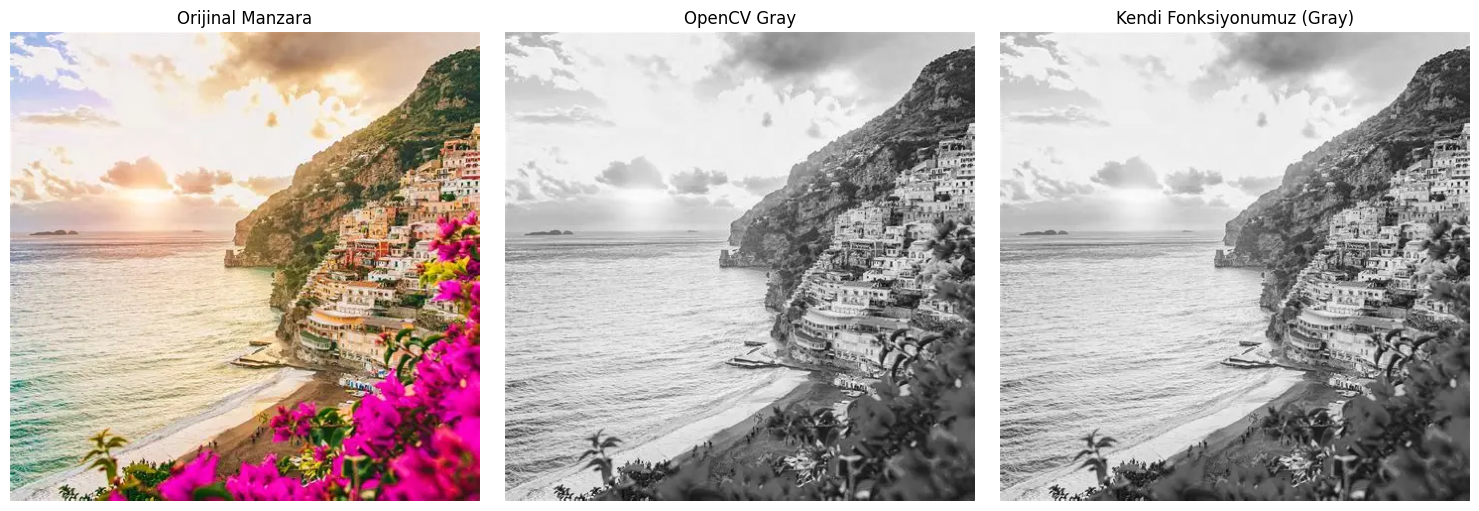

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 'manzara.webp' dosyasını yükle
image_path = '/content/manzara.webp'
img_bgr = cv2.imread(image_path)

if img_bgr is None:
    print("Hata: 'manzara.webp' dosyası yüklenemedi. Lütfen dosya yolunu kontrol edin.")
else:
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 2. OpenCV ile hazır gri tonlama
    img_gray_opencv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 3. Kendi yazdığımız fonksiyon ile gri tonlama
    # Standart parlaklık formülü: Y = 0.299 * R + 0.587 * G + 0.114 * B
    # BGR formatında: kanallar 0=B, 1=G, 2=R
    def custom_rgb_to_gray(img):
        b = img[:, :, 0].astype(float)
        g = img[:, :, 1].astype(float)
        r = img[:, :, 2].astype(float)
        gray = 0.299 * r + 0.587 * g + 0.114 * b
        return np.clip(gray, 0, 255).astype(np.uint8)

    img_gray_custom = custom_rgb_to_gray(img_bgr)

    # 4. Mutlak farkların toplamı (SAD) hesaplama
    absolute_diff = cv2.absdiff(img_gray_opencv, img_gray_custom)
    total_error = np.sum(absolute_diff)

    print(f"Görüntü Boyutu: {img_gray_opencv.shape}")
    print(f"Eşleşen piksellerin mutlak farklarının toplamı (Hata Değeri): {total_error}")

    # 5. Görselleştirme
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.title("Orijinal Manzara")
    plt.imshow(img_rgb)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("OpenCV Gray")
    plt.imshow(img_gray_opencv, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Kendi Fonksiyonumuz (Gray)")
    plt.imshow(img_gray_custom, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()